# ComplaintRouter — Dimensionality Reduction and Clustering

This notebook applies **truncated SVD** to the TF-IDF features (latent semantic analysis, LSA) and asks three
questions:

1. **How many dimensions does product classification need?** A linear SVM is trained on the first *k* SVD
   components for several values of *k* and compared with the same SVM on the full 100k-dimensional TF-IDF matrix.
2. **What does the complaint space look like in 2-D?** SVD components 1–2 and a t-SNE map of a stratified
   sample, split by product.
3. **Which themes appear without labels?** K-means on normalized 100-dimensional LSA vectors, with top terms per
   cluster, agreement with the product labels (ARI / NMI), and the monetary relief rate per cluster.

Everything is fit on the training split only; the test split is used only to score the classifiers in part 1.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    f1_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.svm import LinearSVC

pd.set_option("display.max_colwidth", None)

In [2]:
RANDOM_STATE = 42

DATA_PATH = Path("../data/processed/complaint_router_modeling_data.csv")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SHORT_LABELS = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan",
}
PRODUCT_ORDER = list(SHORT_LABELS)

# Shared TF-IDF configuration used by every notebook in the project
TFIDF_PARAMS = dict(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    sublinear_tf=True,
    max_features=100_000,
)

N_COMPONENTS = 500
K_COMPONENTS = [2, 5, 10, 25, 50, 100, 200, 300, 500]
LSA_DIMS = 100
K_CLUSTERS = [5, 7, 9, 11, 13, 15, 20, 25]
SAMPLE_SIZE = 10_000

# Plot colors
PRIMARY = "#2a78d6"     # main series / highlighted product
SECONDARY = "#eb6834"   # second series
MUTED = "#cfcfcf"       # background points
REFERENCE = "#8c8c8c"   # reference lines

## 1. Load Data

In [3]:
df = pd.read_csv(DATA_PATH, usecols=["Product", "clean_narrative", "monetary_relief", "split"])

train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
del df

y_train = train["Product"].to_numpy()
y_test = test["Product"].to_numpy()

print(f"Training samples: {len(train):,}")
print(f"Testing samples: {len(test):,}")
print("Number of classes:", train["Product"].nunique())

Training samples: 130,000
Testing samples: 32,500
Number of classes: 11


## 2. TF-IDF Features

Same configuration as the classification notebooks, fit on the training split only. The matrix is stored as
`float32` (half the memory of the default `float64`; the values are the same up to floating-point precision), which
also makes the SVD below run in single precision.

In [4]:
start = time.perf_counter()

tfidf = TfidfVectorizer(**TFIDF_PARAMS, dtype=np.float32)
X_train = tfidf.fit_transform(train["clean_narrative"])
X_test = tfidf.transform(test["clean_narrative"])

print(f"TF-IDF fitted in {time.perf_counter() - start:.1f} s")
print("Training TF-IDF shape:", X_train.shape, X_train.dtype)
print("Testing TF-IDF shape:", X_test.shape)

# The raw text is no longer needed
train = train.drop(columns="clean_narrative")
test = test.drop(columns="clean_narrative")

TF-IDF fitted in 56.7 s
Training TF-IDF shape: (130000, 100000) float32
Testing TF-IDF shape: (32500, 100000)


## 3. Truncated SVD (LSA)

`TruncatedSVD` factorizes the sparse TF-IDF matrix directly (no centering, so it works on sparse input) and keeps
the 500 directions with the largest singular values. The projected features are stored as `float32` to save memory.

In [5]:
start = time.perf_counter()

svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
Z_train = svd.fit_transform(X_train).astype(np.float32, copy=False)
Z_test = svd.transform(X_test).astype(np.float32, copy=False)

print(f"SVD fitted in {time.perf_counter() - start:.1f} s")
print("Training SVD shape:", Z_train.shape)
print("Testing SVD shape:", Z_test.shape)
print(f"SVD training features in memory: {Z_train.nbytes / 1e6:.0f} MB")

SVD fitted in 83.5 s
Training SVD shape: (130000, 500)
Testing SVD shape: (32500, 500)
SVD training features in memory: 260 MB


In [6]:
cumulative_variance = np.cumsum(svd.explained_variance_ratio_)

variance_table = pd.DataFrame({
    "components": K_COMPONENTS,
    "cumulative explained variance": cumulative_variance[np.array(K_COMPONENTS) - 1],
})

print(f"Variance explained by component 1: {svd.explained_variance_ratio_[0]:.4f}")
print(f"Variance explained by component 2: {svd.explained_variance_ratio_[1]:.4f}")
variance_table.round(4)

Variance explained by component 1: 0.0031
Variance explained by component 2: 0.0118


,components,cumulative explained variance
0,2,0.0149
1,5,0.0338
2,10,0.0490
3,25,0.0716
4,50,0.0948
5,100,0.1252
6,200,0.1665
7,300,0.1973
8,500,0.2421


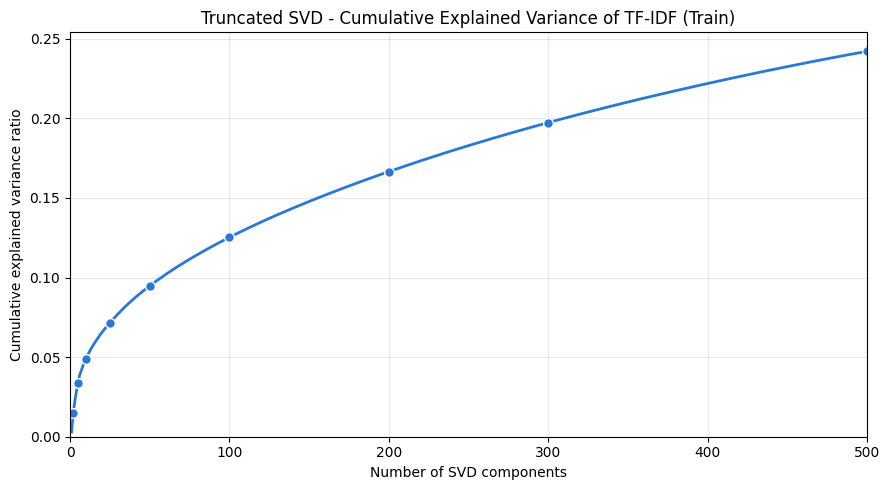

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(np.arange(1, N_COMPONENTS + 1), cumulative_variance, lw=2, color=PRIMARY)
ax.plot(
    K_COMPONENTS,
    cumulative_variance[np.array(K_COMPONENTS) - 1],
    "o",
    markersize=7,
    color=PRIMARY,
    markeredgecolor="white",
)

ax.set_title("Truncated SVD - Cumulative Explained Variance of TF-IDF (Train)")
ax.set_xlabel("Number of SVD components")
ax.set_ylabel("Cumulative explained variance ratio")
ax.set_xlim(0, N_COMPONENTS)
ax.set_ylim(0, None)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "svd_explained_variance.png", dpi=300, bbox_inches="tight")
plt.show()

TF-IDF text features are very high-dimensional and sparse, so even 500 components keep only a modest share of the
total variance: **12.5% with 100 components, 19.7% with 300 and 24.2% with 500**. The curve rises steeply over the
first ~25 components (7.2%) and then flattens slowly. Much of the remaining variance comes from rare words and phrases
that are specific to individual complaints. Because the data is not centered, the first component mostly points
along the "average complaint" direction. That is why it explains *less* variance than the second component here
(0.31% vs. 1.18%).

## 4. Classification Accuracy vs. Number of Components

Randomized SVD returns the components ordered by singular value, so the **first *k* columns of the 500-component
projection approximate a *k*-component truncated SVD**. This lets one SVD fit serve every *k*: the classifier for
each *k* is trained on `Z_train[:, :k]`.

The classifier is `LinearSVC(C=0.5)` for every *k*, and the same model trained on the full TF-IDF matrix gives the
reference line.

In [8]:
start = time.perf_counter()

full_svm = LinearSVC(C=0.5, max_iter=5000, random_state=RANDOM_STATE)
full_svm.fit(X_train, y_train)
full_seconds = time.perf_counter() - start

full_pred = full_svm.predict(X_test)
full_macro_f1 = f1_score(y_test, full_pred, average="macro")
full_accuracy = accuracy_score(y_test, full_pred)

print(f"Full TF-IDF LinearSVC ({X_train.shape[1]:,} features, {full_seconds:.1f} s)")
print(f"  Test macro-F1: {full_macro_f1:.4f}")
print(f"  Test accuracy: {full_accuracy:.4f}")

del full_svm, full_pred

Full TF-IDF LinearSVC (100,000 features, 65.8 s)
  Test macro-F1: 0.7819
  Test accuracy: 0.8040


In [9]:
component_rows = []

for k in K_COMPONENTS:
    start = time.perf_counter()

    clf = LinearSVC(C=0.5, max_iter=5000, random_state=RANDOM_STATE)
    clf.fit(Z_train[:, :k], y_train)
    seconds = time.perf_counter() - start

    pred = clf.predict(Z_test[:, :k])
    component_rows.append({
        "components": k,
        "macro_f1": f1_score(y_test, pred, average="macro"),
        "accuracy": accuracy_score(y_test, pred),
        "train_seconds": seconds,
    })
    print(f"k = {k:>3}: macro-F1 {component_rows[-1]['macro_f1']:.4f}, "
          f"accuracy {component_rows[-1]['accuracy']:.4f} ({seconds:.1f} s)")

component_results = pd.DataFrame(component_rows)
component_results["share of full macro-F1"] = component_results["macro_f1"] / full_macro_f1

k =   2: macro-F1 0.1025, accuracy 0.2763 (0.8 s)


k =   5: macro-F1 0.1624, accuracy 0.3632 (3.3 s)


k =  10: macro-F1 0.3461, accuracy 0.5467 (5.9 s)


k =  25: macro-F1 0.5516, accuracy 0.6727 (13.0 s)


k =  50: macro-F1 0.6345, accuracy 0.7204 (20.7 s)


k = 100: macro-F1 0.6890, accuracy 0.7490 (32.0 s)


k = 200: macro-F1 0.7210, accuracy 0.7640 (59.9 s)


k = 300: macro-F1 0.7343, accuracy 0.7725 (82.3 s)


k = 500: macro-F1 0.7487, accuracy 0.7813 (121.7 s)


In [10]:
target_f1 = 0.95 * full_macro_f1
reached = component_results[component_results["macro_f1"] >= target_f1]

if len(reached) > 0:
    k_95 = int(reached["components"].iloc[0])
    print(f"{k_95} SVD components retain at least 95% of the full TF-IDF macro-F1 "
          f"({component_results.loc[reached.index[0], 'macro_f1']:.4f} vs {full_macro_f1:.4f}).")
else:
    k_95 = None
    print("None of the tested sizes reaches 95% of the full TF-IDF macro-F1.")

component_results.round(4)

500 SVD components retain at least 95% of the full TF-IDF macro-F1 (0.7487 vs 0.7819).


,components,macro_f1,accuracy,train_seconds,share of full macro-F1
0,2,0.1025,0.2763,0.8264,0.1311
1,5,0.1624,0.3632,3.2639,0.2078
2,10,0.3461,0.5467,5.9040,0.4427
3,25,0.5516,0.6727,12.9766,0.7055
4,50,0.6345,0.7204,20.7304,0.8115
5,100,0.6890,0.7490,32.0300,0.8812
6,200,0.7210,0.7640,59.8511,0.9221
7,300,0.7343,0.7725,82.2803,0.9392
8,500,0.7487,0.7813,121.7326,0.9576


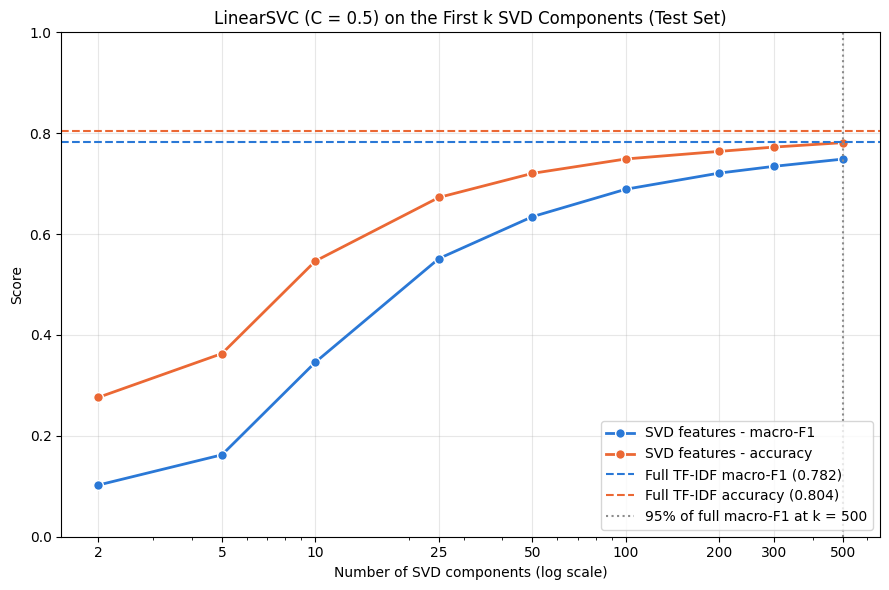

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(component_results["components"], component_results["macro_f1"], "-o", lw=2, markersize=7,
        color=PRIMARY, markeredgecolor="white", label="SVD features - macro-F1")
ax.plot(component_results["components"], component_results["accuracy"], "-o", lw=2, markersize=7,
        color=SECONDARY, markeredgecolor="white", label="SVD features - accuracy")

ax.axhline(full_macro_f1, ls="--", lw=1.5, color=PRIMARY,
           label=f"Full TF-IDF macro-F1 ({full_macro_f1:.3f})")
ax.axhline(full_accuracy, ls="--", lw=1.5, color=SECONDARY,
           label=f"Full TF-IDF accuracy ({full_accuracy:.3f})")

if k_95 is not None:
    ax.axvline(k_95, ls=":", lw=1.5, color=REFERENCE, label=f"95% of full macro-F1 at k = {k_95}")

ax.set_xscale("log")
ax.set_xticks(K_COMPONENTS)
ax.set_xticklabels(K_COMPONENTS)
ax.set_ylim(0, 1)
ax.set_title("LinearSVC (C = 0.5) on the First k SVD Components (Test Set)")
ax.set_xlabel("Number of SVD components (log scale)")
ax.set_ylabel("Score")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig(FIG_DIR / "svd_components_vs_macro_f1.png", dpi=300, bbox_inches="tight")
plt.show()

### Components vs. Performance Findings

| Components (k) | 2 | 5 | 10 | 25 | 50 | 100 | 200 | 300 | 500 | Full TF-IDF |
|---|---|---|---|---|---|---|---|---|---|---|
| Test macro-F1 | 0.103 | 0.162 | 0.346 | 0.552 | 0.635 | 0.689 | 0.721 | 0.734 | 0.749 | **0.782** |
| Test accuracy | 0.276 | 0.363 | 0.547 | 0.673 | 0.720 | 0.749 | 0.764 | 0.773 | 0.781 | **0.804** |
| Share of full macro-F1 | 13% | 21% | 44% | 71% | 81% | 88% | 92% | 94% | 96% | 100% |

- **Steep, then slow.** Macro-F1 climbs fastest between 5 and 50 components (0.16 → 0.64), then gains only about
  0.03 per doubling of k. Accuracy stays above macro-F1 throughout, because the large classes are learned first and
  small products such as Debt/Credit Mgmt and Prepaid Card need more dimensions.
- **About 500 components are needed to keep ~95% of the full TF-IDF macro-F1.** 300 components reach 93.9%
  (0.734) and 500 reach 95.8% (0.749 vs. 0.782). Even the 500-dimensional projection loses 0.033 macro-F1
  against the sparse 100,000-feature model.
- **About the reference line.** It is this notebook's own `LinearSVC(C=0.5)` without class weights (0.782). The
  tuned baseline in `baselines/linear_svm.ipynb` (C = 0.25, balanced) reaches 0.784, essentially the same.
- **SVD does not save training time for a linear model.** The dense 500-component SVM took about 148 s to train,
  while the sparse full TF-IDF model took 71 s. The value of SVD is the compact dense input it gives non-linear
  models, not speed for linear ones.
- **Link to the non-linear models.** The non-linear notebooks use SVD-300 features. Here a *linear* SVM on SVD-300
  reaches 0.734. The MLP (0.747) recovers only a little of the gap, HistGradientBoosting (0.734) merely matches the
  linear model, and kNN (0.709) falls below it. None of them reaches the linear models on full TF-IDF
  (Logistic Regression 0.776, LinearSVC 0.782–0.784). The roughly 0.05 macro-F1 lost in the SVD-300 compression
  is the main reason the non-linear models trail.

In [12]:
# The sparse TF-IDF matrices and test projections are no longer needed
del X_train, X_test, Z_test

## 5. 2-D Visualization

A stratified sample of 10,000 training complaints (same product mix as the training set) is plotted twice:

- **SVD components 1 and 2** (a linear projection).
- **t-SNE** on the first 50 SVD components after L2 normalization (so Euclidean distance matches cosine
  similarity). t-SNE preserves local neighborhoods, not global distances.

With 11 products, a single scatter plot with 11 colors is hard to read, so each panel highlights one product
against all other sampled complaints in gray. The last panel marks the median position of each product.

In [13]:
sample_idx, _ = train_test_split(
    np.arange(len(train)),
    train_size=SAMPLE_SIZE,
    stratify=y_train,
    random_state=RANDOM_STATE,
)
sample_idx = np.sort(sample_idx)
y_sample = y_train[sample_idx]

print(f"Sample size: {len(sample_idx):,}")
print(pd.Series(y_sample).map(SHORT_LABELS).value_counts().to_string())

Sample size: 10,000
Credit Reporting        2154
Debt Collection         1538
Checking/Savings        1231
Credit Card             1231
Money Transfer           923
Student Loan             615
Mortgage                 615
Vehicle Loan             615
Payday/Personal Loan     462
Prepaid Card             308
Debt/Credit Mgmt         308


In [14]:
def plot_product_panels(coords, labels, title, xlabel, ylabel, path):
    fig, axes = plt.subplots(3, 4, figsize=(16, 12), sharex=True, sharey=True)
    axes = axes.ravel()

    for ax, product in zip(axes, PRODUCT_ORDER):
        mask = labels == product
        ax.scatter(coords[~mask, 0], coords[~mask, 1], s=2, color=MUTED, alpha=0.5,
                   linewidths=0, rasterized=True)
        ax.scatter(coords[mask, 0], coords[mask, 1], s=4, color=PRIMARY, alpha=0.7,
                   linewidths=0, rasterized=True)
        ax.set_title(f"{SHORT_LABELS[product]} (n = {mask.sum():,})", fontsize=11)

    ax = axes[-1]
    ax.scatter(coords[:, 0], coords[:, 1], s=2, color=MUTED, alpha=0.5, linewidths=0, rasterized=True)
    for product in PRODUCT_ORDER:
        center = np.median(coords[labels == product], axis=0)
        ax.plot(center[0], center[1], "o", markersize=6, color="black")
        ax.annotate(SHORT_LABELS[product], center, textcoords="offset points", xytext=(4, 4), fontsize=8)
    ax.set_title("Product medians", fontsize=11)

    for ax in axes[8:]:
        ax.set_xlabel(xlabel)
    for ax in axes[::4]:
        ax.set_ylabel(ylabel)

    fig.suptitle(title, fontsize=15)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()

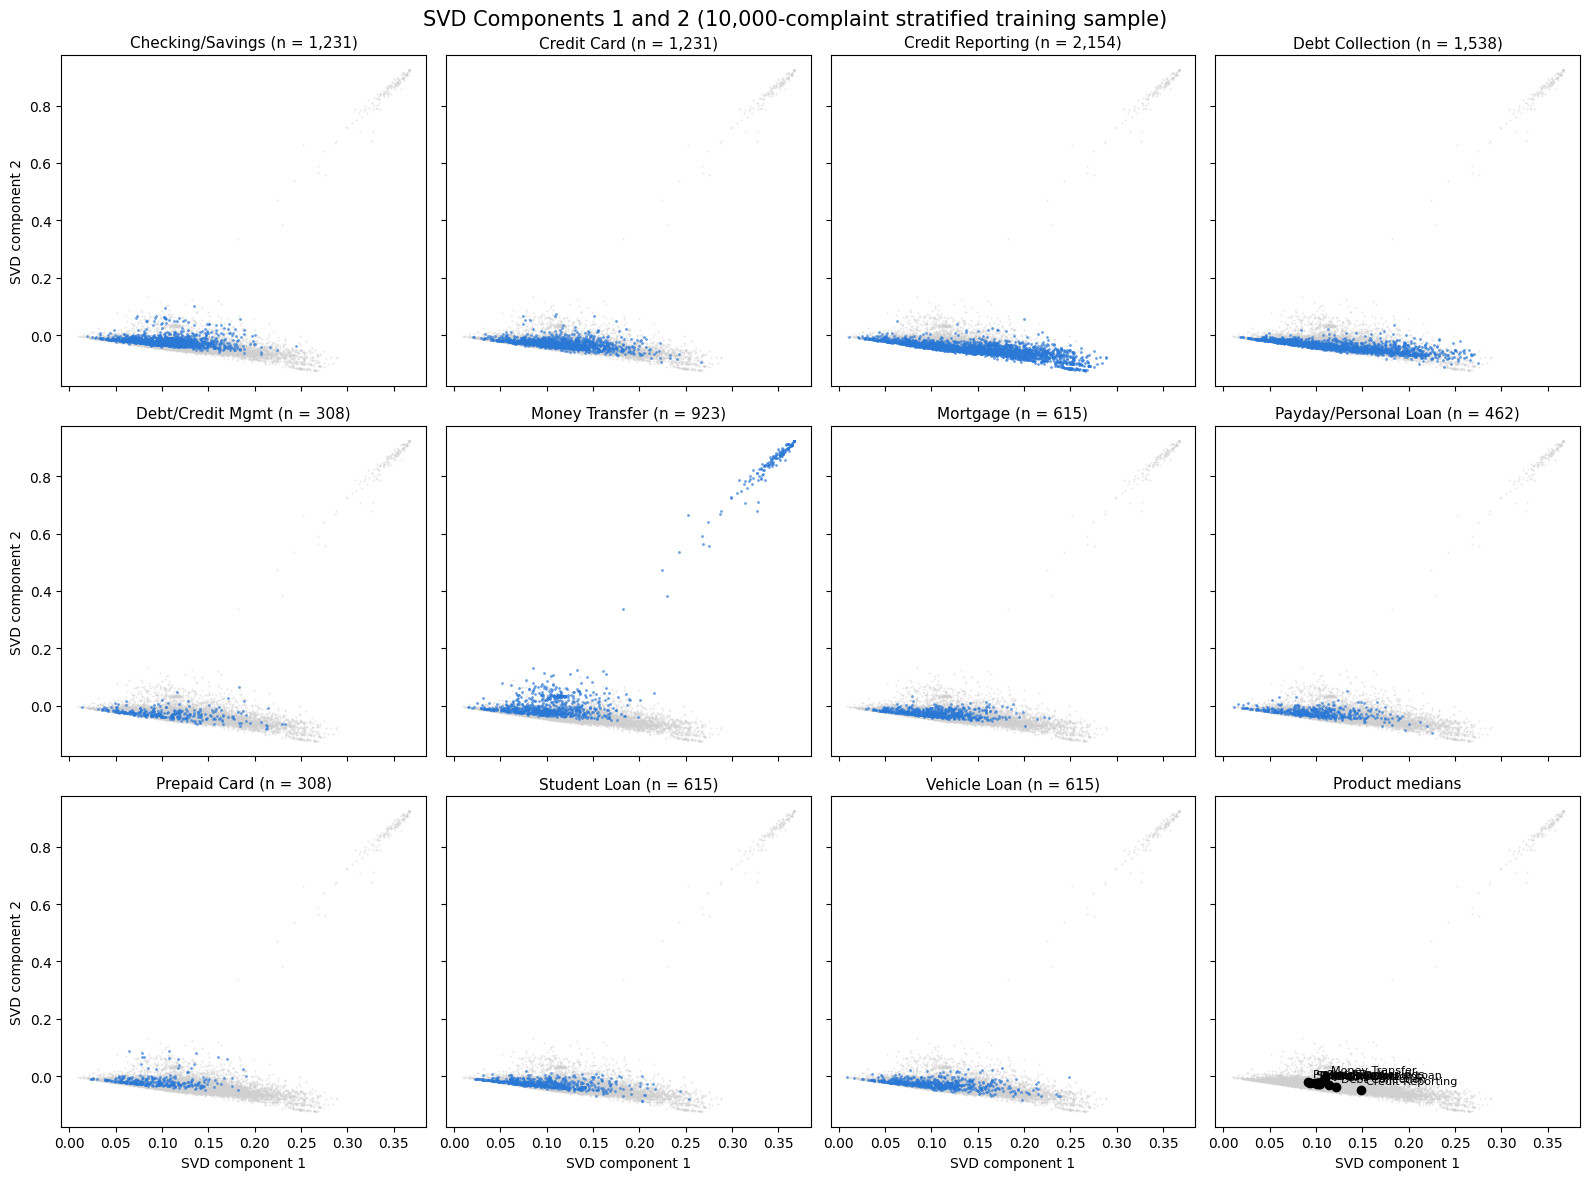

In [15]:
plot_product_panels(
    Z_train[sample_idx, :2],
    y_sample,
    f"SVD Components 1 and 2 ({SAMPLE_SIZE:,}-complaint stratified training sample)",
    "SVD component 1",
    "SVD component 2",
    FIG_DIR / "svd_2d_scatter.png",
)

t-SNE finished in 34.8 s


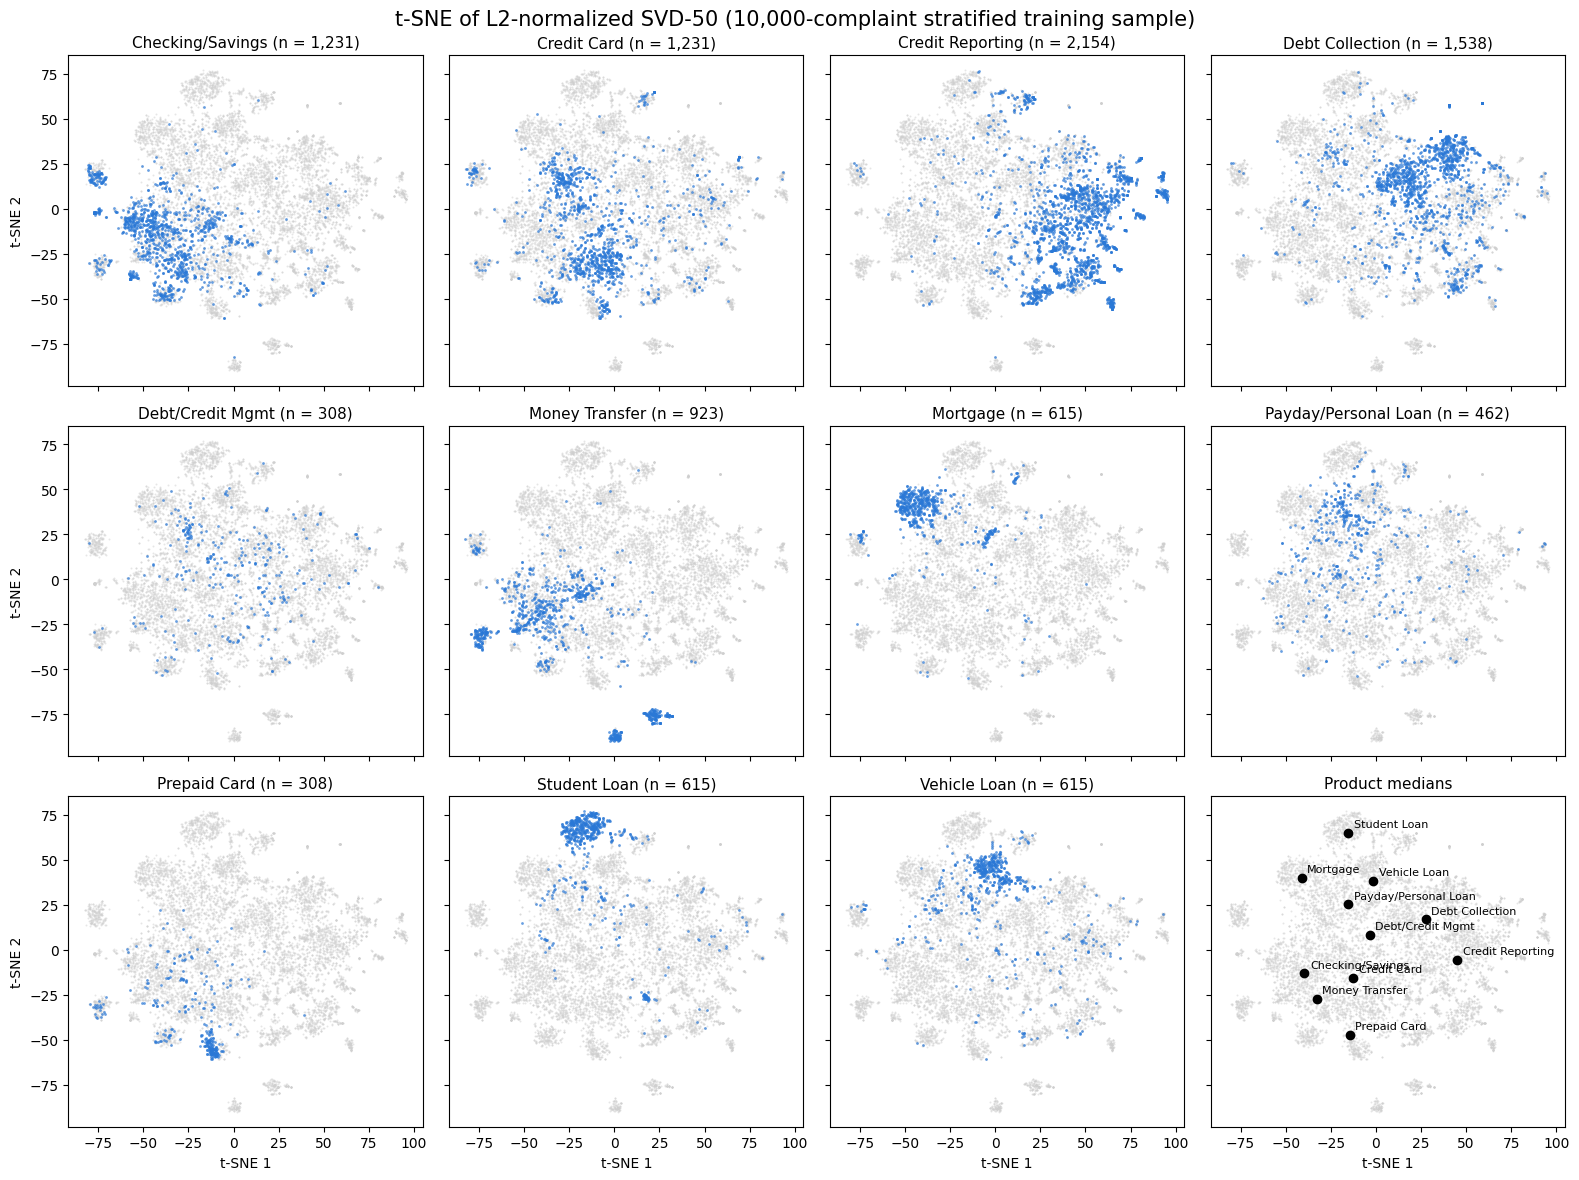

In [16]:
Z50_sample = normalize(Z_train[sample_idx, :50])

start = time.perf_counter()
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
    n_jobs=4,
)
tsne_coords = tsne.fit_transform(Z50_sample)
print(f"t-SNE finished in {time.perf_counter() - start:.1f} s")

plot_product_panels(
    tsne_coords,
    y_sample,
    f"t-SNE of L2-normalized SVD-50 ({SAMPLE_SIZE:,}-complaint stratified training sample)",
    "t-SNE 1",
    "t-SNE 2",
    FIG_DIR / "tsne_2d_scatter.png",
)

### 2-D Visualization Findings

- **SVD components 1–2.** In the first two linear directions the products sit almost on top of each other; all
  product medians fall in one small region, which matches the macro-F1 of 0.10 at k = 2.
  - Component 1 mainly orders complaints along the shared "average complaint" vocabulary.
  - Component 2 is dominated by a tight streak of **Money Transfer** complaints reaching values near 0.9. This
    matches the January 2025 Cash App / Zelle template campaign seen in the EDA and in the k-means clusters below:
    one near-identical letter, repeated thousands of times, is frequent enough to claim the second-largest SVD
    direction.
- **t-SNE.** The non-linear map shows much more structure.
  - **Student Loan, Mortgage and Vehicle Loan** form compact islands of their own.
  - **Credit Reporting and Debt Collection** share one large region on the right, with sub-islands that
    correspond to dispute-letter templates.
  - **Checking/Savings, Credit Card, Money Transfer and Prepaid Card** overlap on the left. Money Transfer also
    has two small, very tight islands at the bottom: the template campaign again.
  - **Debt/Credit Mgmt and Payday/Personal Loan** are scattered over the whole map with no region of their own.
    They are the products that are hardest to separate by vocabulary.

## 6. K-Means Clustering on LSA Vectors

Following the standard LSA recipe, each training complaint is represented by its first 100 SVD components,
L2-normalized so that k-means groups complaints by cosine similarity. K-means is run for several values of k
(5 random initializations each). The inertia curve (elbow) and the silhouette score on the 10,000-complaint
sample are used to choose k; k = 11 is also examined because it matches the number of products.

In [17]:
Z_lsa = normalize(Z_train[:, :LSA_DIMS])
print("LSA feature shape:", Z_lsa.shape, Z_lsa.dtype)

kmeans_models = {}
sweep_rows = []

for k in K_CLUSTERS:
    start = time.perf_counter()
    km = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE)
    km.fit(Z_lsa)
    seconds = time.perf_counter() - start

    silhouette = silhouette_score(Z_lsa[sample_idx], km.labels_[sample_idx])
    kmeans_models[k] = km
    sweep_rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette, "seconds": seconds})
    print(f"k = {k:>2}: inertia {km.inertia_:,.0f}, silhouette {silhouette:.4f} ({seconds:.1f} s)")

kmeans_sweep = pd.DataFrame(sweep_rows).set_index("k")

LSA feature shape: (130000, 100) float32


k =  5: inertia 96,873, silhouette 0.0497 (1.8 s)


k =  7: inertia 93,777, silhouette 0.0510 (2.1 s)


k =  9: inertia 90,497, silhouette 0.0651 (2.9 s)


k = 11: inertia 88,575, silhouette 0.0652 (3.1 s)


k = 13: inertia 86,533, silhouette 0.0667 (3.6 s)


k = 15: inertia 83,956, silhouette 0.0811 (3.7 s)


k = 20: inertia 80,152, silhouette 0.0871 (4.6 s)


k = 25: inertia 76,966, silhouette 0.0943 (8.6 s)


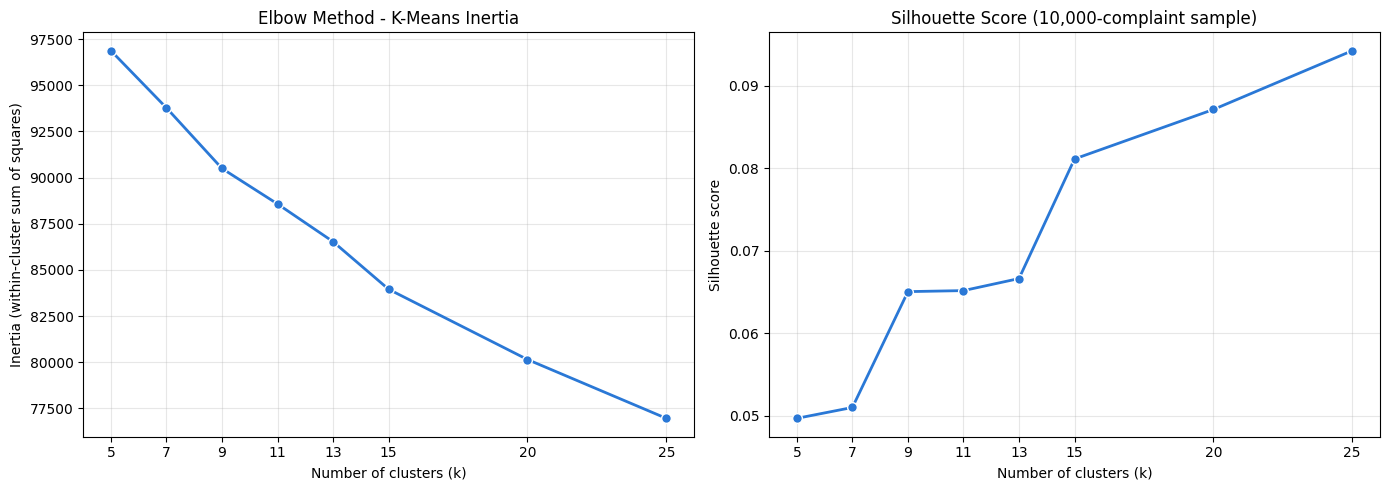

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(kmeans_sweep.index, kmeans_sweep["inertia"], "-o", lw=2, markersize=7,
             color=PRIMARY, markeredgecolor="white")
axes[0].set_title("Elbow Method - K-Means Inertia")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")

axes[1].plot(kmeans_sweep.index, kmeans_sweep["silhouette"], "-o", lw=2, markersize=7,
             color=PRIMARY, markeredgecolor="white")
axes[1].set_title(f"Silhouette Score ({SAMPLE_SIZE:,}-complaint sample)")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

for ax in axes:
    ax.set_xticks(K_CLUSTERS)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "kmeans_k_selection.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
# Selection rule: the k with the highest silhouette score on the sample.
CHOSEN_K = int(kmeans_sweep["silhouette"].idxmax())
analysis_ks = sorted({CHOSEN_K, 11})

print(f"Chosen k (highest silhouette): {CHOSEN_K}")
print("Clusterings analyzed below:", analysis_ks)
kmeans_sweep.round(4)

Chosen k (highest silhouette): 25
Clusterings analyzed below: [11, 25]


,inertia,silhouette,seconds
k,,,
5,96873.2188,0.0497,1.8037
7,93777.3828,0.0510,2.1103
9,90496.8359,0.0651,2.8572
11,88574.6953,0.0652,3.1376
13,86532.8984,0.0667,3.6406
15,83956.0078,0.0811,3.7499
20,80151.7812,0.0871,4.6280
25,76965.8203,0.0943,8.6497


### Choosing k

- **The inertia curve has no clear elbow.** It falls steadily from 96,873 (k = 5) to 76,966 (k = 25), which is
  typical for text embeddings.
- **The silhouette score rises almost monotonically with k:** 0.050 at k = 5, 0.065 at k = 9–11, 0.081 at
  k = 15 and **0.094 at k = 25**. The selection rule (highest silhouette) therefore picks **k = 25**, the largest
  value tested.
- **The silhouette values stay below 0.1 for every k.** The clusters overlap heavily, so k-means here finds themes
  rather than well-separated groups.
- **Why k = 25 is kept rather than extending the search.** Larger k might score slightly higher, but 25 clusters
  is already about the most that can be named by hand, and the finest clusters at k = 25 are already single
  template letters. The **k = 11** clustering (one cluster per product, silhouette 0.065) is also reported for a
  like-for-like comparison with the product labels.

### Top Terms per Cluster

Cluster centers live in the normalized 100-dimensional LSA space. Mapping them back to the TF-IDF vocabulary with
`svd.inverse_transform` (padding the 400 unused components with zeros) gives a weight for every term; the 12
highest-weighted terms describe each cluster. The table also shows each cluster's size, its most common product,
and its monetary relief rate (complaints without a final outcome are ignored).

In [20]:
feature_names = tfidf.get_feature_names_out()
relief_train = train["monetary_relief"].to_numpy()
overall_relief_rate = np.nanmean(relief_train)


def cluster_summary(k, n_terms=12):
    km = kmeans_models[k]
    labels = km.labels_

    padding = np.zeros((k, N_COMPONENTS - LSA_DIMS), dtype=km.cluster_centers_.dtype)
    centers_tfidf = svd.inverse_transform(np.hstack([km.cluster_centers_, padding]))

    rows = []
    for cluster in range(k):
        mask = labels == cluster
        product_share = pd.Series(y_train[mask]).value_counts(normalize=True)
        top = np.argsort(centers_tfidf[cluster])[::-1][:n_terms]
        rows.append({
            "cluster": cluster,
            "size": int(mask.sum()),
            "share": mask.mean(),
            "dominant product": SHORT_LABELS[product_share.index[0]],
            "dominant share": product_share.iloc[0],
            "monetary relief rate": np.nanmean(relief_train[mask]),
            "top terms": ", ".join(feature_names[top]),
        })
    return pd.DataFrame(rows).set_index("cluster")


cluster_tables = {k: cluster_summary(k) for k in analysis_ks}
print(f"Overall monetary relief rate (train): {overall_relief_rate:.4f}")

Overall monetary relief rate (train): 0.0576


In [21]:
print(f"k = {CHOSEN_K} (chosen)")
cluster_tables[CHOSEN_K].sort_values("size", ascending=False).round(3)

k = 25 (chosen)


,size,share,dominant product,dominant share,monetary relief rate,top terms
cluster,,,,,,
14,12131,0.093,Credit Reporting,0.599,0.004,"credit, report, credit report, accounts, information, inquiries, account, removed, remove, reporting, fraudulent, inaccurate"
16,8967,0.069,Checking/Savings,0.646,0.124,"bank, account, funds, check, deposit, dollaramount, checking, closed, money, checking account, deposited, told"
4,8933,0.069,Credit Reporting,0.702,0.002,"reporting, credit, fcra, inaccurate, information, credit reporting, report, fair credit, fair, reporting act, act, credit report"
6,8897,0.068,Debt Collection,0.204,0.063,"phone, called, told, said, number, email, account, asked, times, company, received, sent"
7,7729,0.059,Payday/Personal Loan,0.284,0.081,"loan, payment, dollaramount, payments, pay, paid, month, told, make, balance, fees, company"
5,7570,0.058,Vehicle Loan,0.163,0.045,"financial, complaint, account, despite, regarding, matter, loan, request, provide, issue, consumer, dollaramount"
23,6853,0.053,Credit Card,0.756,0.154,"card, credit card, credit, account, dollaramount, bank, called, charge, received, told, charges, did"
8,6742,0.052,Debt Collection,0.776,0.005,"debt, company, collection, credit, collect, collector, debt collector, owe, sent, received, letter, owed"
17,5923,0.046,Debt Collection,0.790,0.001,"debt, collection, validation, fdcpa, debt collection, alleged, collection practices, alleged debt, fair debt, practices act, reporting, practices"


In [22]:
if CHOSEN_K == 11:
    print("The chosen k is already 11 (the number of products); see the table above.")
else:
    print("k = 11 (number of products)")
    display(cluster_tables[11].sort_values("size", ascending=False).round(3))

k = 11 (number of products)


,size,share,dominant product,dominant share,monetary relief rate,top terms
cluster,,,,,,
1,29128,0.224,Checking/Savings,0.346,0.126,"account, money, card, bank, dollaramount, told, called, said, funds, sent, did, received"
3,21125,0.162,Credit Reporting,0.584,0.004,"credit, report, credit report, accounts, account, information, identity, theft, identity theft, inquiries, fraudulent, removed"
10,13812,0.106,Credit Card,0.233,0.100,"account, dollaramount, funds, despite, bank, complaint, financial, dispute, issue, provided, transaction, provide"
5,12929,0.099,Mortgage,0.405,0.020,"loan, mortgage, car, company, vehicle, payment, dollaramount, insurance, paid, pay, told, payments"
2,12900,0.099,Credit Card,0.340,0.127,"payment, dollaramount, payments, late, paid, pay, account, credit, balance, fees, card, month"
6,12050,0.093,Debt Collection,0.805,0.002,"debt, collection, validation, collect, credit, debt collection, company, original, fdcpa, account, alleged, collector"
4,11686,0.090,Credit Reporting,0.677,0.002,"reporting, credit, fcra, inaccurate, information, report, credit reporting, credit report, fair, fair credit, act, account"
8,6198,0.048,Student Loan,0.914,0.007,"loans, student, loan, mohela, student loans, student loan, forbearance, payments, repayment, payment, plan, education"
0,5401,0.042,Credit Reporting,0.736,0.002,"15, usc, 15 usc, consumer, 1681, reporting, information, consumer reporting, section, reporting agency, report, agency"


### Agreement With Product Labels

**Adjusted Rand Index (ARI)** and **Normalized Mutual Information (NMI)** compare each clustering with the true
products (0 = no agreement beyond chance, 1 = identical partitions). They are shown for every k in the sweep.

In [23]:
agreement = pd.DataFrame([
    {
        "k": k,
        "ARI": adjusted_rand_score(y_train, kmeans_models[k].labels_),
        "NMI": normalized_mutual_info_score(y_train, kmeans_models[k].labels_),
    }
    for k in K_CLUSTERS
]).set_index("k")

agreement.round(4)

,ARI,NMI
k,,
5,0.2875,0.3382
7,0.2537,0.3466
9,0.2699,0.3787
11,0.2137,0.3343
13,0.2043,0.3304
15,0.2236,0.3584
20,0.1830,0.3490
25,0.1861,0.3579


### Cluster × Product Heatmap

Each row is a cluster and shows how its complaints are distributed across products (rows sum to 1). Rows are
sorted by dominant product, and each row label lists the cluster's three strongest terms.

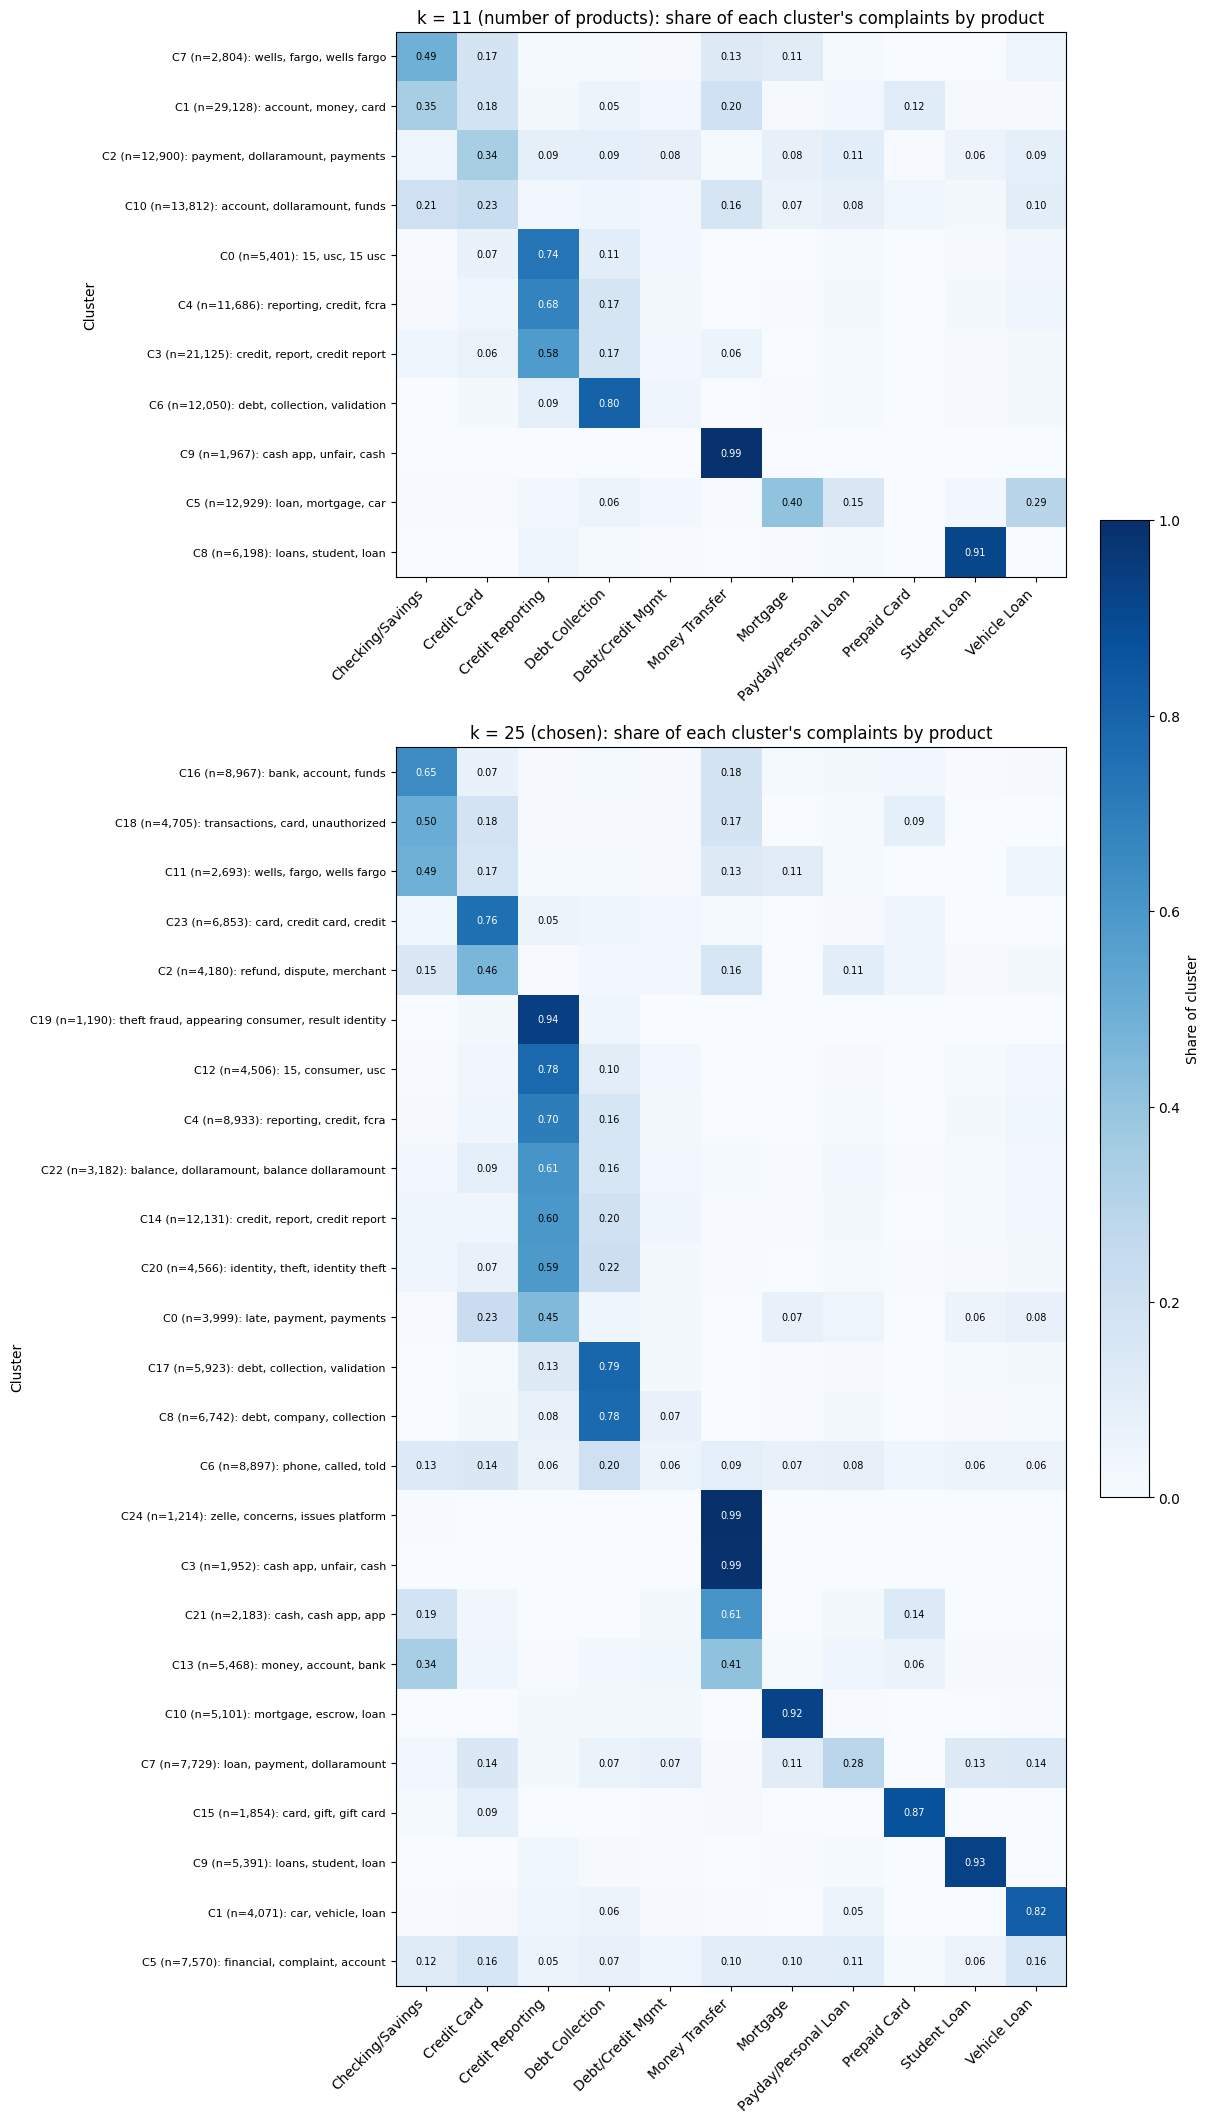

In [24]:
def cluster_product_matrix(k):
    matrix = pd.crosstab(
        pd.Series(kmeans_models[k].labels_, name="cluster"),
        pd.Series(y_train, name="product").map(SHORT_LABELS),
        normalize="index",
    )
    matrix = matrix.reindex(columns=[SHORT_LABELS[p] for p in PRODUCT_ORDER], fill_value=0.0)
    values = matrix.to_numpy()
    row_order = np.lexsort((-values.max(axis=1), values.argmax(axis=1)))
    return matrix.iloc[row_order]


fig, axes = plt.subplots(
    len(analysis_ks),
    1,
    figsize=(12, 0.42 * sum(analysis_ks) + 3 * len(analysis_ks)),
    gridspec_kw={"height_ratios": analysis_ks},
    layout="constrained",
    squeeze=False,
)

for ax, k in zip(axes[:, 0], analysis_ks):
    matrix = cluster_product_matrix(k)
    summary = cluster_tables[k]

    image = ax.imshow(matrix.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")

    row_labels = [
        f"C{c} (n={summary.loc[c, 'size']:,}): " + ", ".join(summary.loc[c, "top terms"].split(", ")[:3])
        for c in matrix.index
    ]
    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(row_labels, fontsize=8)
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_xticklabels(matrix.columns, rotation=45, ha="right")

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix.iat[i, j]
            if value >= 0.05:
                ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if value > 0.6 else "black")

    if k == CHOSEN_K and k == 11:
        label = "chosen; equals the number of products"
    elif k == CHOSEN_K:
        label = "chosen"
    else:
        label = "number of products"
    ax.set_title(f"k = {k} ({label}): share of each cluster's complaints by product")
    ax.set_ylabel("Cluster")

fig.colorbar(image, ax=axes[:, 0].tolist(), shrink=0.5, label="Share of cluster")

plt.savefig(FIG_DIR / "kmeans_cluster_product_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### Monetary Relief Rate per Cluster

Clusters sorted by monetary relief rate, compared with the overall training rate.

In [25]:
for k in analysis_ks:
    table = cluster_tables[k][["size", "dominant product", "monetary relief rate"]].copy()
    table["vs overall"] = table["monetary relief rate"] / overall_relief_rate
    print(f"\nk = {k} (overall rate {overall_relief_rate:.4f})")
    print(table.sort_values("monetary relief rate", ascending=False).round(3).to_string())


k = 11 (overall rate 0.0576)
          size  dominant product  monetary relief rate  vs overall
cluster                                                           
2        12900       Credit Card                 0.127       2.204
1        29128  Checking/Savings                 0.126       2.192
7         2804  Checking/Savings                 0.111       1.927
10       13812       Credit Card                 0.100       1.741
5        12929          Mortgage                 0.020       0.343
8         6198      Student Loan                 0.007       0.124
3        21125  Credit Reporting                 0.004       0.074
4        11686  Credit Reporting                 0.002       0.033
6        12050   Debt Collection                 0.002       0.031
0         5401  Credit Reporting                 0.002       0.029
9         1967    Money Transfer                 0.000       0.000

k = 25 (overall rate 0.0576)
          size      dominant product  monetary relief rate  vs overal

### Cluster Themes

Theme names for the chosen **k = 25** clustering, based on each cluster's top terms (largest cluster first). The
monetary relief rate is computed over training complaints with a final outcome; the overall rate is 5.8%.

| Cluster | Size | Dominant product (share) | Top terms | Theme | Monetary relief rate |
|---|---|---|---|---|---|
| C14 | 12,131 | Credit Reporting (60%) | credit report, accounts, inquiries, removed, fraudulent, inaccurate | Credit-report disputes (remove accounts / inquiries) | 0.4% |
| C16 | 8,967 | Checking/Savings (65%) | bank, account, funds, check, deposit, closed | Bank deposits, checks and frozen / closed accounts | 12.4% |
| C4 | 8,933 | Credit Reporting (70%) | reporting, fcra, inaccurate, information, fair credit reporting act | FCRA "inaccurate information" dispute letters | 0.2% |
| C6 | 8,897 | Debt Collection (20%) | phone, called, told, said, number, email, times | Customer-service runaround (cross-product) | 6.3% |
| C7 | 7,729 | Payday/Personal Loan (28%) | loan, payment, payments, pay, balance, fees | Loan payments, balances and fees (cross-product) | 8.1% |
| C5 | 7,570 | Vehicle Loan (16%) | financial, complaint, despite, regarding, matter, request | Formal complaint-letter language (cross-product) | 4.5% |
| C23 | 6,853 | Credit Card (76%) | card, credit card, account, charge, charges | Credit card accounts and charges | 15.4% |
| C8 | 6,742 | Debt Collection (78%) | debt, collection, collector, owe, letter, owed | Debt collectors and collection letters | 0.5% |
| C17 | 5,923 | Debt Collection (79%) | debt, validation, fdcpa, alleged debt, collection practices | FDCPA debt-validation demands | 0.1% |
| C13 | 5,468 | Money Transfer (41%) | money, account, bank, sent, transfer, funds | Sending and transferring money | 9.0% |
| C9 | 5,391 | Student Loan (93%) | student loans, mohela, forbearance, repayment plan | Student loans (MOHELA, forbearance, repayment) | 0.7% |
| C10 | 5,101 | Mortgage (92%) | mortgage, escrow, insurance, home, property, taxes | Mortgage escrow, insurance and taxes | 1.5% |
| C18 | 4,705 | Checking/Savings (50%) | transactions, unauthorized, fraud, claim, charges, denied | Unauthorized transactions and fraud claims | 19.3% |
| C20 | 4,566 | Credit Reporting (59%) | identity theft, victim, fraudulent accounts, theft report | Identity theft | 0.5% |
| C12 | 4,506 | Credit Reporting (78%) | 15 usc, 1681, consumer reporting agency, section, privacy | Legal-citation letters (15 U.S.C. § 1681) | 0.1% |
| C2 | 4,180 | Credit Card (46%) | refund, dispute, merchant, charge, paypal, purchase | Merchant disputes and refunds | 20.2% |
| C1 | 4,071 | Vehicle Loan (82%) | car, vehicle, repossession, insurance, dealership | Auto loans and repossession | 2.6% |
| C0 | 3,999 | Credit Reporting (45%) | late payment(s), reported, report, time | Late payments reported to the bureaus | 4.3% |
| C22 | 3,182 | Credit Reporting (61%) | balance dollaramount, date opened, opened balance | Account-listing dispute templates (balance / date opened) | 2.1% |
| C11 | 2,693 | Checking/Savings (49%) | wells fargo, account, bank, claim, fraud | Wells Fargo complaints (a company-name cluster) | 11.2% |
| C21 | 2,183 | Money Transfer (61%) | cash app, app account, transaction, support, closed | Cash App account problems | 0.7% |
| C3 | 1,952 | Money Transfer (99%) | cash app, unfair, resolution, unprotected, fraud platform, vulnerable | Cash App template campaign (January 2025) | 0.0% |
| C15 | 1,854 | Prepaid Card (87%) | gift card, use, declined, amex, american express, online | Gift cards that don't work | **32.6%** |
| C24 | 1,214 | Money Transfer (99%) | zelle, issues platform, handling disputes, cfpb lawsuit, failed investigate | Zelle template campaign | 0.1% |
| C19 | 1,190 | Credit Reporting (94%) | theft fraud, appearing consumer, hard inquiries, accounts collections | Identity-theft hard-inquiry template | 0.0% |

**What the themes show:**
- **Product clusters.** About half of the clusters map cleanly onto one product, such as student loans (93%),
  mortgage (92%) and auto loans (82%).
- **Cross-product clusters.** Others group complaints by *issue or writing style*.
  - The customer-service runaround (C6), loan payments (C7) and formal letter language (C5) are clusters where no
    single product holds more than 30%.
  - Issue clusters such as unauthorized transactions (C18) and merchant disputes (C2) mix bank, card and
    money-transfer complaints.
  - This is why agreement with the product labels is low.
- **Template clusters.** Several clusters are **template campaigns**:
  - **C3 (Cash App) and C24 (Zelle)** together hold 3,166 training complaints. They contain the January 2025
    template campaign found in the EDA (about 2,300 near-identical narratives) plus close variants.
  - **C12, C19 and C22** are credit-repair dispute templates.
  - Because Credit Reporting has only 103 narratives from 2026, the credit-reporting clusters describe complaints
    from 2023–2025.
- **Monetary relief follows the theme.**
  - **Highest rates:** gift cards (32.6%, 5.7× the overall rate), merchant disputes and refunds (20.2%),
    unauthorized transactions (19.3%) and credit card charges (15.4%).
  - **Lowest rates:** every template cluster and every credit-reporting and debt-collection theme is at 0.0–0.5%.
- **A company forms its own cluster.** Wells Fargo is a complete cluster (C11) at both k = 11 and k = 25. A single
  company name is distinctive enough to define a theme.

## Dimensionality Reduction and Clustering Summary

- **Components vs. accuracy.** A LinearSVC (C = 0.5) on the first k SVD components reaches macro-F1:
  - 0.103 at k = 2
  - 0.635 at k = 50
  - 0.689 at k = 100
  - 0.734 at k = 300
  - 0.749 at k = 500

  The same model on full TF-IDF reaches **0.782** (accuracy 0.804). The tuned `baselines/linear_svm.ipynb`
  reference is 0.784. **About 500 components are needed to keep ~95% of the full-TF-IDF macro-F1** (95.8%; 300
  components keep 93.9%).
- **Link to the non-linear models.** Compressing to SVD-300 costs a linear model about 0.05 macro-F1. The
  non-linear models trained on SVD-300 do not win it back: MLP 0.747, HistGradientBoosting 0.734, kNN 0.709. Sparse
  linear models on full TF-IDF remain the best product classifiers.
- **Explained variance.** The SVD keeps 12.5% of the TF-IDF variance with 100 components, 19.7% with 300 and 24.2%
  with 500. Most of the variance is rare, complaint-specific vocabulary that the classifier does not need.
- **2-D views.**
  - SVD components 1–2 do not separate the products. Component 2 is taken over by the Cash App / Zelle template
    campaign.
  - t-SNE separates Student Loan, Mortgage and Vehicle Loan into clean islands. It overlaps Credit Reporting with
    Debt Collection, and Checking/Savings with Credit Card, Money Transfer and Prepaid Card. It leaves
    Debt/Credit Mgmt and Payday/Personal Loan scattered.
- **K-means (LSA-100, L2-normalized).**
  - The inertia curve has no clear elbow, and the silhouette rises almost monotonically to **0.094 at k = 25**,
    the chosen k.
  - Agreement with the product labels is low: **ARI 0.186 / NMI 0.358** at k = 25 and **ARI 0.214 / NMI 0.334**
    at k = 11. The best values in the sweep are ARI 0.288 (k = 5) and NMI 0.379 (k = 9).
  - The clusters capture *issue types and template letters* as much as products.
  - Monetary relief rates range from **32.6%** (gift cards) and about 20% (merchant disputes and refunds,
    unauthorized transactions) down to **0–0.5%** for template campaigns, credit-report disputes and debt
    collection. This mirrors the product and company effects in the monetary relief notebook.